In [ ]:
#1. 그래프 설정
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
from statsmodels.tsa.seasonal import STL

fonts = {f.name for f in font_manager.fontManager.ttflist}
for name in ['AppleGothic', 'Malgun Gothic', 'NanumGothic']:
    if name in fonts:
        plt.rcParams['font.family'] = name
        break
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
print('실행 Python:', sys.executable)

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


실행 Python: /opt/anaconda3/bin/python


In [2]:
########## 2. 폴더 안의 실거래가 파일만 읽기 ##########
# 프로젝트 폴더 또는 바로 아래 notebooks 폴더에서 실행
filename = '서울_아파트_매매_실거래가_2017-2026_통합.xlsx'
root = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / filename).exists()), None)
if root is None:
    raise FileNotFoundError('프로젝트 폴더에서 실행하세요: ' + filename)
source = root / filename
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Workbook contains no default style')
    raw = pd.read_excel(source, sheet_name='아파트(매매) 실거래가', dtype=str)
print('분석 파일:', source.name)
print(f'원본: {len(raw):,}행 / {len(raw.columns)}개 열')
display(raw.head(3))

분석 파일: 서울_아파트_매매_실거래가_2017-2026_통합.xlsx
원본: 547,735행 / 21개 열


,NO,시군구,번지,본번,부번,단지명,...,도로명,해제사유발생일,거래유형,중개사소재지,등기일자,주택유형
0,1,서울특별시 중구 신당동,850,0850,0000,신당푸르지오,...,다산로36길 110,-,-,-,-,아파트
1,2,서울특별시 성북구 돈암동,609-1,0609,0001,한신,...,성북로4길 52,-,-,-,-,아파트
2,3,서울특별시 용산구 효창동,3-3,0003,0003,효삼골드빌,...,효창원로93길 14,-,-,-,-,아파트


In [3]:
########## 3. 서울 아파트 매매만 남기고 날짜·금액 정리 ##########
df = raw.copy()
df.columns = df.columns.str.strip()
for col in df.columns:
    df[col] = df[col].astype('string').str.strip()

def numeric(series):
    return pd.to_numeric(series.str.replace(',', '', regex=False), errors='coerce').astype(float)

df['가격_만원'] = numeric(df['거래금액(만원)'])
df['면적_m2'] = numeric(df['전용면적(㎡)'])
ym = numeric(df['계약년월']).astype('Int64').astype('string')
day = numeric(df['계약일']).astype('Int64').astype('string').str.zfill(2)
df['계약일자'] = pd.to_datetime(ym + day, format='%Y%m%d', errors='coerce')
df['자치구'] = df['시군구'].str.extract(r'^서울특별시\s+(\S+구)(?:\s|$)', expand=False)
cancelled = ~df['해제사유발생일'].fillna('').isin(['', '-', '0'])
seoul_apt = df['자치구'].notna() & df['주택유형'].eq('아파트').fillna(False)
valid = df['계약일자'].notna() & df['가격_만원'].gt(0) & df['면적_m2'].gt(0)
keep = seoul_apt & ~cancelled & valid.fillna(False)
display(pd.Series({
    '원본 행': len(df),
    '서울 아파트 외': int((~seoul_apt).sum()),
    '서울 아파트 해제 거래': int((seoul_apt & cancelled).sum()),
    '나머지 중 날짜·가격·면적 오류': int((seoul_apt & ~cancelled & ~valid.fillna(False)).sum()),
    '분석 거래': int(keep.sum()),
}, name='건수').to_frame())
# 동일 날짜·금액·층이어도 다른 세대일 수 있어 임의로 중복 제거하지 않음
df = df.loc[keep].copy().sort_values('계약일자')
if df.empty:
    raise ValueError('분석 가능한 서울 아파트 거래가 없습니다.')
df['가격_억원'] = df['가격_만원'] / 10000
df['m2당_만원'] = df['가격_만원'] / df['면적_m2']
df['월'] = df['계약일자'].dt.to_period('M').dt.to_timestamp()
print(f"실제 계약 기간: {df['계약일자'].min():%Y-%m-%d} ~ {df['계약일자'].max():%Y-%m-%d}")
print(f"자치구 수: {df['자치구'].nunique()} / 분석 거래: {len(df):,}건")

,건수
원본 행,547735
서울 아파트 외,0
서울 아파트 해제 거래,17606
나머지 중 날짜·가격·면적 오류,0
분석 거래,530129


실제 계약 기간: 2017-10-28 ~ 2026-10-26
자치구 수: 25 / 분석 거래: 530,129건


In [4]:
########## 4. 월별 시계열과 3·6·12개월 이동평균 ##########
monthly = df.groupby('월').agg(
    거래량=('가격_억원', 'size'), 평균가격=('가격_억원', 'mean'),
    중위가격=('가격_억원', 'median'), m2당중위가격=('m2당_만원', 'median')
).asfreq('MS')
# 거래가 없는 달의 가격은 결측 유지, 이동평균은 직전 N개월이 모두 있어야 계산
monthly['거래량'] = monthly['거래량'].fillna(0).astype(int)
for window in [3, 6, 12]:
    monthly[f'MA{window}'] = monthly['중위가격'].rolling(window, min_periods=window).mean()
monthly['전월대비_pct'] = monthly['중위가격'].pct_change(fill_method=None) * 100
monthly['전년동월대비_pct'] = monthly['중위가격'].pct_change(12, fill_method=None) * 100
monthly['m2당_전년동월대비_pct'] = monthly['m2당중위가격'].pct_change(12, fill_method=None) * 100
print('가격 단위: 억원 / 면적당 가격: 만원/㎡ / 변화율: %')
print('첫 달과 마지막 달은 일부 기간만 포함될 수 있으며, 신고 지연에 따른 누락도 있을 수 있습니다.')
display(monthly.tail(12).round(2))

가격 단위: 억원 / 면적당 가격: 만원/㎡ / 변화율: %
첫 달과 마지막 달은 일부 기간만 포함될 수 있으며, 신고 지연에 따른 누락도 있을 수 있습니다.


,거래량,평균가격,중위가격,m2당중위가격,MA3,MA6,MA12,전월대비_pct,전년동월대비_pct,m2당_전년동월대비_pct
월,,,,,,,,,,
2025-11-01,3390,13.08,9.95,"1,342.94",10.50,10.12,10.19,-7.01,4.74,-0.56
2025-12-01,4775,10.93,8.95,"1,264.85",9.87,9.78,10.19,-10.05,-0.53,-4.02
2026-01-01,5374,11.73,9.45,"1,268.11",9.45,9.78,10.14,5.59,-5.50,-9.45
2026-02-01,5797,11.15,9.00,"1,225.24",9.13,9.82,9.90,-4.76,-24.24,-21.93
2026-03-01,5516,10.51,8.45,"1,183.80",8.97,9.42,9.63,-6.11,-27.78,-23.72
2026-04-01,8666,12.20,9.25,"1,302.38",8.90,9.17,9.65,9.47,2.21,-0.52
2026-05-01,8991,12.85,9.90,"1,389.18",9.20,9.17,9.64,7.03,-1.00,0.52
2026-06-01,5325,12.23,9.60,"1,307.86",9.58,9.28,9.52,-3.03,-12.73,-9.47
2026-07-01,5863,11.40,9.00,"1,379.07",9.50,9.20,9.49,-6.25,-4.26,5.99


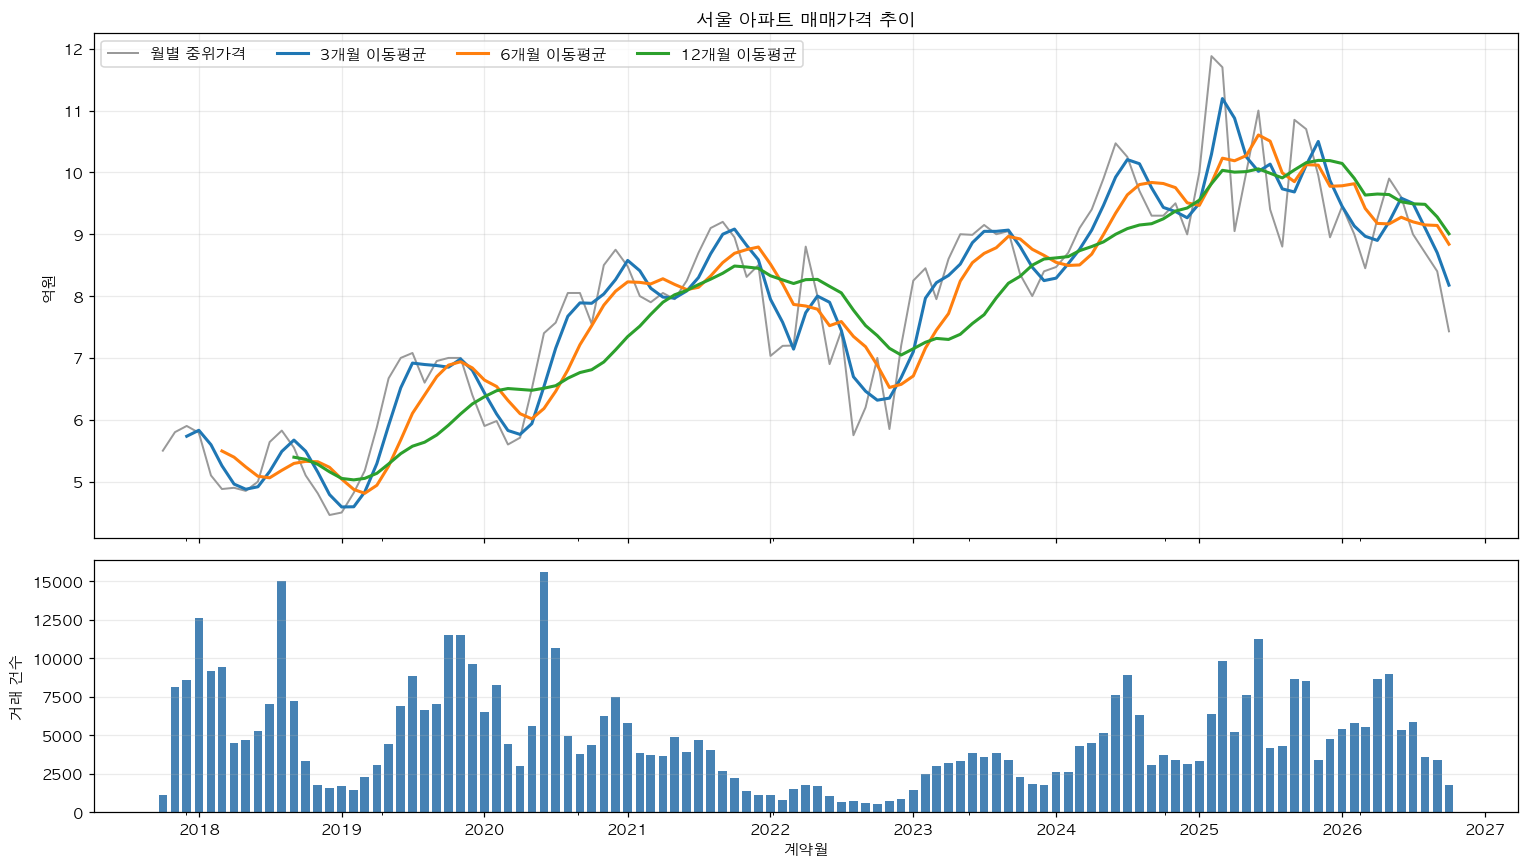

In [5]:
########## 5. 가격 흐름과 거래량 함께 보기 ##########
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
monthly['중위가격'].plot(ax=axes[0], color='0.6', linewidth=1.3, label='월별 중위가격', x_compat=True)
for window in [3, 6, 12]:
    monthly[f'MA{window}'].plot(ax=axes[0], linewidth=2, label=f'{window}개월 이동평균', x_compat=True)
axes[0].set(title='서울 아파트 매매가격 추이', ylabel='억원')
axes[0].legend(ncol=4)
axes[0].grid(alpha=0.25)
axes[1].bar(monthly.index, monthly['거래량'], width=22, color='steelblue')
axes[1].set(ylabel='거래 건수', xlabel='계약월')
axes[1].grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

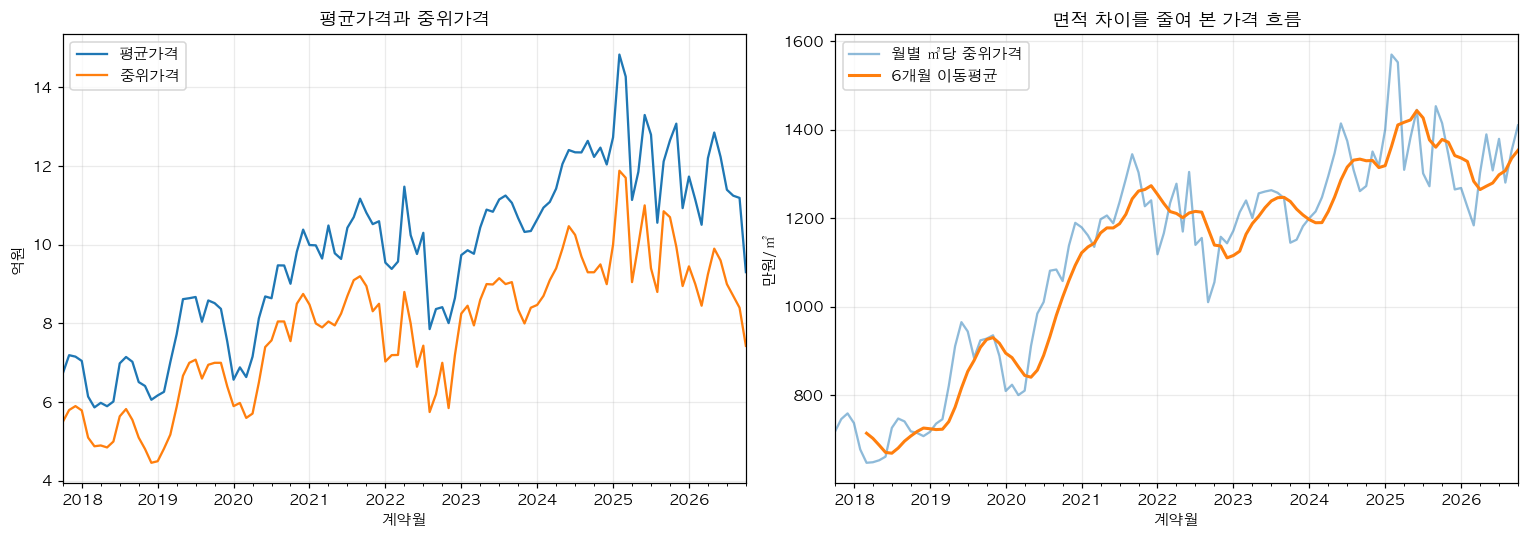

In [6]:
########## 6. 평균·중위가격 및 면적당 가격 비교 ##########
# 평균은 고가 거래에 민감함. 면적당 가격도 지역·단지 구성 변화의 영향을 받음
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
monthly[['평균가격', '중위가격']].plot(ax=axes[0])
axes[0].set(title='평균가격과 중위가격', ylabel='억원', xlabel='계약월')
monthly['m2당중위가격'].plot(ax=axes[1], label='월별 ㎡당 중위가격', alpha=0.5)
monthly['m2당중위가격'].rolling(6, min_periods=6).mean().plot(ax=axes[1], label='6개월 이동평균', linewidth=2)
axes[1].set(title='면적 차이를 줄여 본 가격 흐름', ylabel='만원/㎡', xlabel='계약월')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

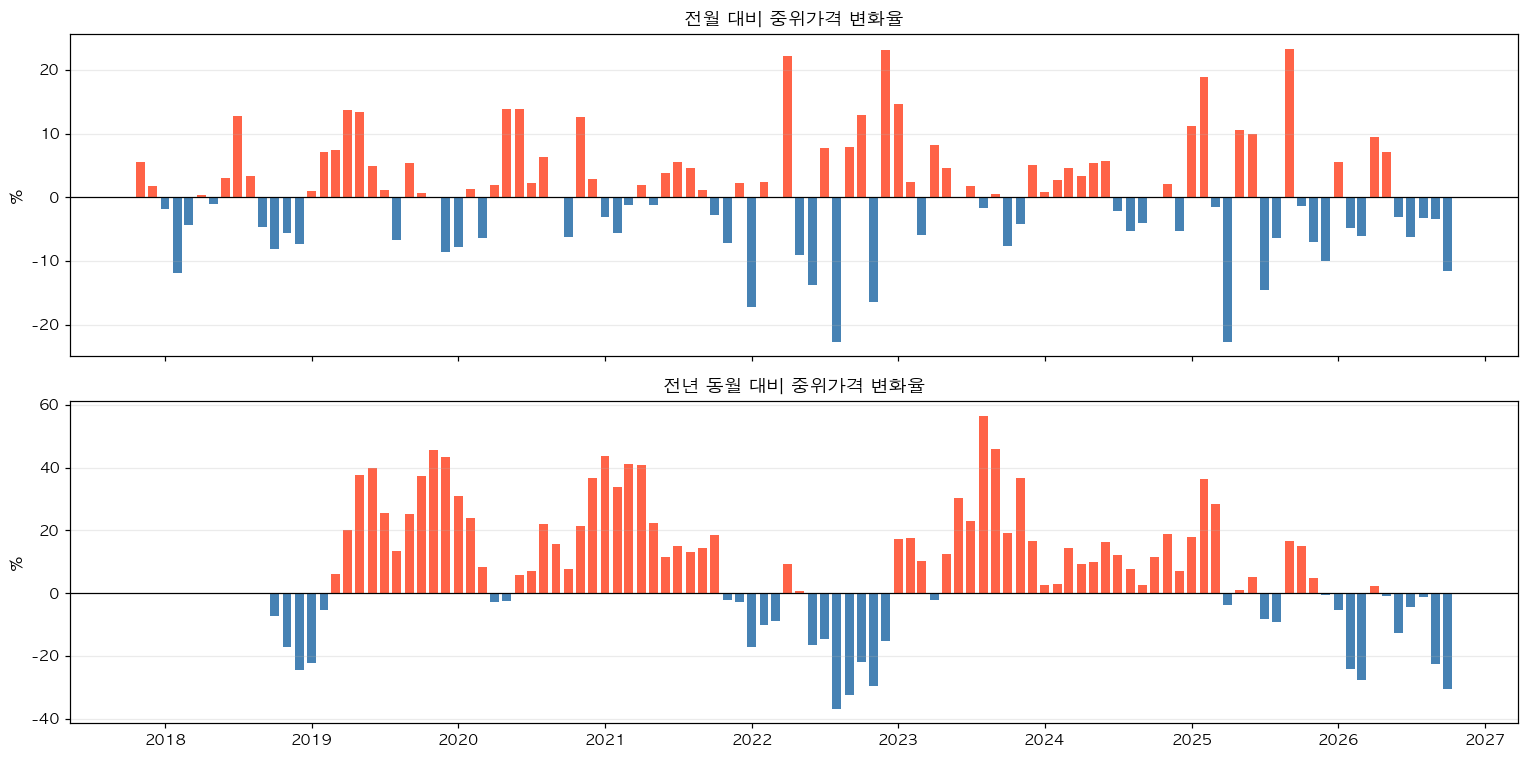

In [7]:
########## 7. 전월·전년 동월 대비 변화율 ##########
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, col, title in zip(axes, ['전월대비_pct', '전년동월대비_pct'], ['전월 대비 중위가격 변화율', '전년 동월 대비 중위가격 변화율']):
    values = monthly[col]
    ax.bar(monthly.index, values, width=22, color=np.where(values >= 0, 'tomato', 'steelblue'))
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set(title=title, ylabel='%')
    ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

최근 3개 계약월: 2026-08 ~ 2026-10 (마지막 달 잠정)


,거래량,중위가격_억원,m2당중위가격_만원
자치구,,,
강남구,264,27.72,"3,678.64"
서초구,242,21.00,"2,778.99"
용산구,89,20.80,"2,385.75"
성동구,134,17.95,"2,502.17"
동작구,240,15.28,"1,904.70"
마포구,241,15.00,"1,906.33"
중구,85,14.90,"1,775.09"
광진구,116,14.85,"1,862.80"
송파구,542,14.00,"2,332.04"


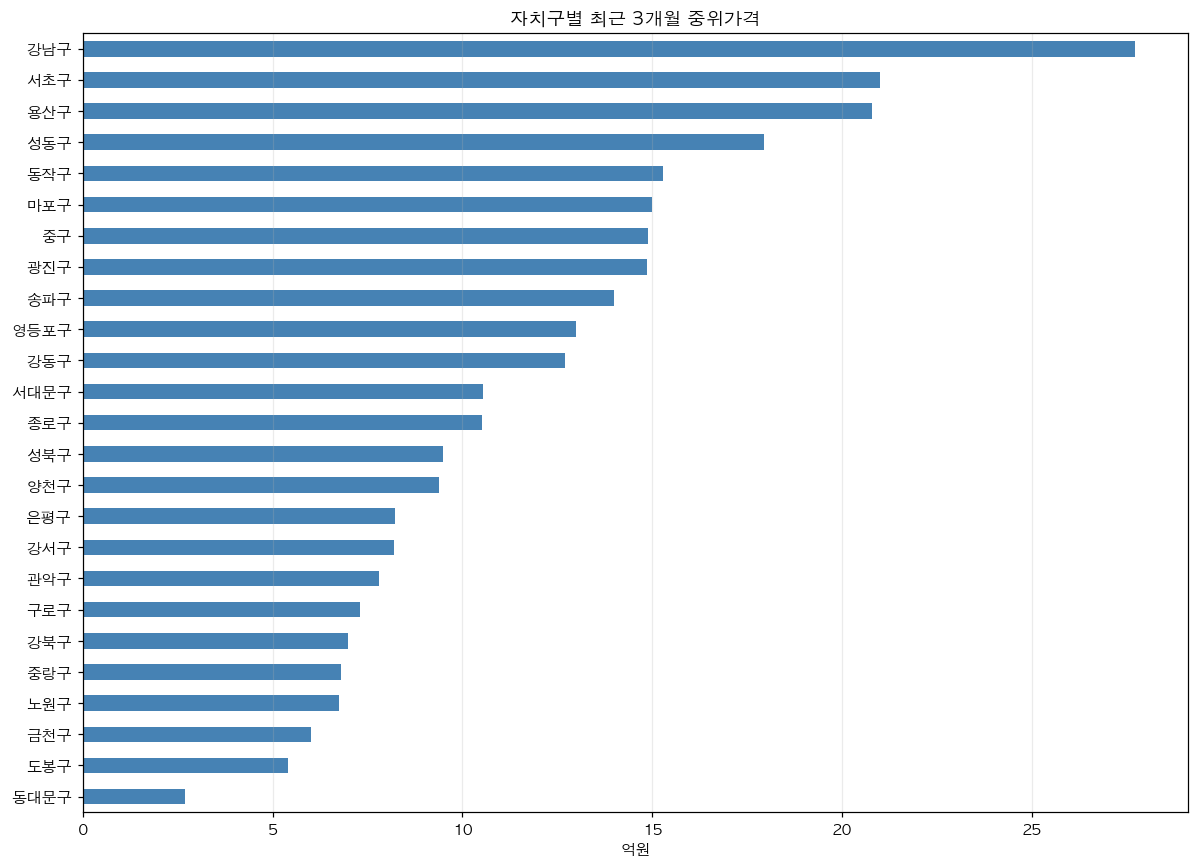

In [8]:
########## 8. 최근 3개월 자치구별 가격 현황 ##########
latest = monthly.index.max()
recent_start = latest - pd.DateOffset(months=2)
recent = df[df['월'].between(recent_start, latest)]
district = recent.groupby('자치구').agg(
    거래량=('가격_억원', 'size'), 중위가격_억원=('가격_억원', 'median'),
    m2당중위가격_만원=('m2당_만원', 'median')
).sort_values('중위가격_억원', ascending=False)
print(f'최근 3개 계약월: {recent_start:%Y-%m} ~ {latest:%Y-%m} (마지막 달 잠정)')
display(district.round(2))
ax = district['중위가격_억원'].sort_values().plot.barh(figsize=(11, 8), color='steelblue')
ax.set(title='자치구별 최근 3개월 중위가격', xlabel='억원', ylabel='')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

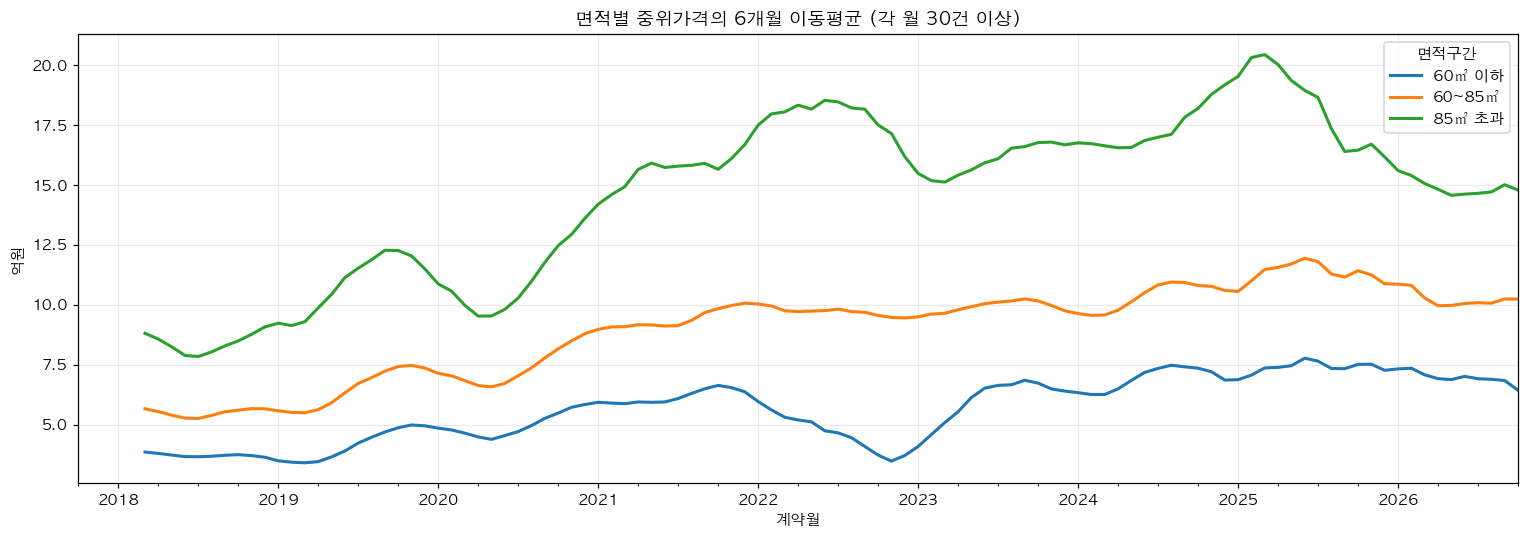

In [9]:
########## 9. 면적별 가격 흐름 비교 ##########
# 같은 면적대 안에서도 지역·단지·연식 구성은 달라질 수 있음
df['면적구간'] = pd.cut(df['면적_m2'], bins=[0, 60, 85, np.inf], labels=['60㎡ 이하', '60~85㎡', '85㎡ 초과'])
area_price = df.groupby(['월', '면적구간'], observed=True)['가격_억원'].median().unstack().reindex(monthly.index)
area_count = df.groupby(['월', '면적구간'], observed=True).size().unstack().reindex(monthly.index).fillna(0)
# 월 30건 미만 구간은 표본이 적어 그래프에서 제외
area_ma = area_price.where(area_count >= 30).rolling(6, min_periods=6).mean()
ax = area_ma.plot(figsize=(14, 5), linewidth=2)
ax.set(title='면적별 중위가격의 6개월 이동평균 (각 월 30건 이상)', ylabel='억원', xlabel='계약월')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

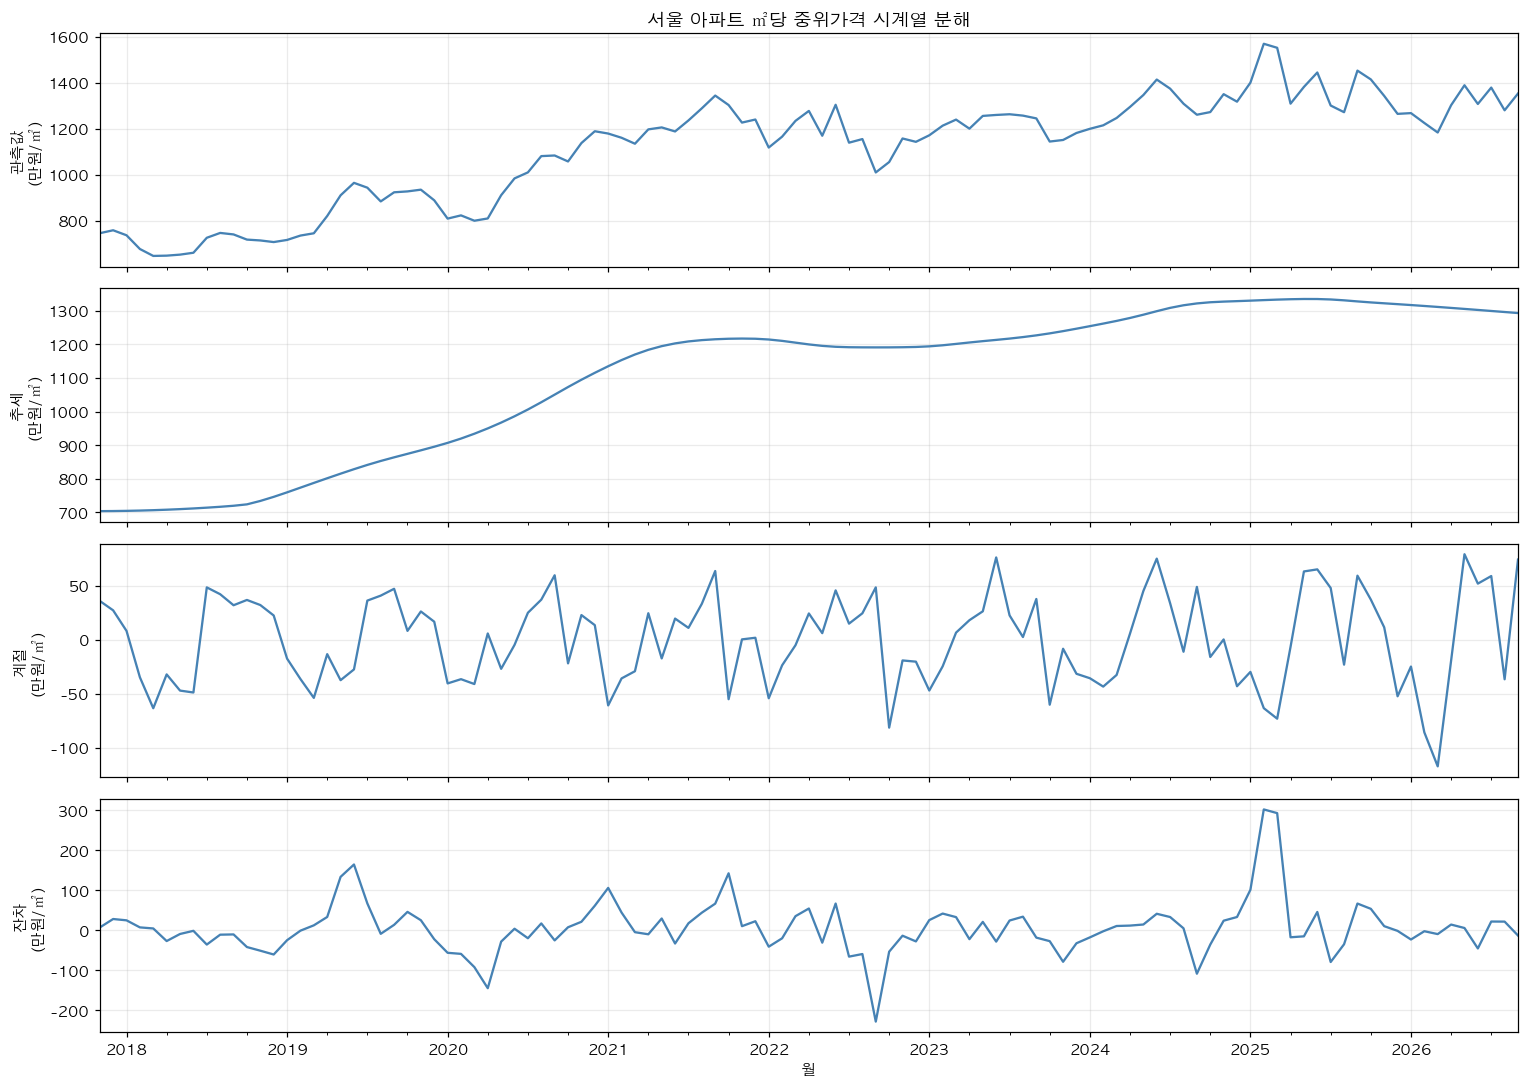

In [10]:
########## 10. 시계열을 추세·계절·잔차로 나누기 ##########
# STL: 12개월 주기의 반복 패턴을 탐색. 계절성이 실제 존재한다는 증명은 아님
# 양 끝 달은 부분 집계 가능성이 있어 제외, 결측월은 임의로 보간하지 않음
series = monthly['m2당중위가격'].iloc[1:-1].astype(float)
if len(series) >= 36 and series.notna().all():
    stl = STL(series, period=12, robust=True).fit()
    decomposition = pd.DataFrame({'관측값': series, '추세': stl.trend, '계절': stl.seasonal, '잔차': stl.resid})
    fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
    for ax, col in zip(axes, decomposition.columns):
        decomposition[col].plot(ax=ax, color='steelblue')
        ax.set_ylabel(col + '\n(만원/㎡)')
        ax.grid(alpha=0.25)
    axes[0].set_title('서울 아파트 ㎡당 중위가격 시계열 분해')
    plt.tight_layout()
    plt.show()
else:
    print('STL 생략: 양 끝 달 제외 후 연속된 36개월 이상의 관측값이 필요합니다.')

In [11]:
########## 11. 최근 흐름을 숫자로 확인 ##########
# 마지막 달은 잠정치로 따로 표시하고, 직전 달로 변화 흐름을 요약
display(monthly[['거래량', '중위가격', 'MA3', 'MA6', 'MA12', '전월대비_pct', '전년동월대비_pct']].tail(3).round(2))
if len(monthly) >= 2:
    reference = monthly.index[-2]
    row = monthly.loc[reference]
    print(f'직전 계약월 {reference:%Y-%m}: 중위가격 {row["중위가격"]:.2f}억원 / 거래량 {row["거래량"]:,.0f}건')
    print(f'전월 대비 {row["전월대비_pct"]:+.2f}% / 전년 동월 대비 {row["전년동월대비_pct"]:+.2f}%')
    if pd.notna(row['MA3']) and pd.notna(row['MA12']):
        gap = (row['MA3'] / row['MA12'] - 1) * 100
        print(f'3개월 이동평균은 12개월 이동평균보다 {gap:+.2f}% 차이')
print('실거래 표본의 변화 흐름이며, 동일 아파트의 가치 변동률이나 공식 가격지수가 아닙니다.')
print('최근 거래의 신고 지연, 거래 지역·면적 구성 변화, 물가 미조정에 유의해 해석합니다.')

,거래량,중위가격,MA3,MA6,MA12,전월대비_pct,전년동월대비_pct
월,,,,,,,
2026-08-01,3607,8.70,9.10,9.15,9.48,-3.33,-1.14
2026-09-01,3394,8.40,8.70,9.14,9.28,-3.45,-22.58
2026-10-01,1796,7.43,8.18,8.84,9.01,-11.55,-30.56


직전 계약월 2026-09: 중위가격 8.40억원 / 거래량 3,394건
전월 대비 -3.45% / 전년 동월 대비 -22.58%
3개월 이동평균은 12개월 이동평균보다 -6.24% 차이
실거래 표본의 변화 흐름이며, 동일 아파트의 가치 변동률이나 공식 가격지수가 아닙니다.
최근 거래의 신고 지연, 거래 지역·면적 구성 변화, 물가 미조정에 유의해 해석합니다.
